# <font color = Blue> **Trabalho Final — Problema 05 - Gasolina EUA**

**`Objetivo do trabalho`**:  modelar um *problema real* e fazer predição utilizando os modelos de séries temporais estudados na disciplina.

**`Problema Real`**: Modelagem e predição de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária - **de 08/02/1991 a 20/01/2017**.

**`Tarefa`**: encontrar o melhor modelo e fazer a predição (**forecast**) de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária para um horizonte **`h`**, que será definido adiante.


## <font color = Blue> **Configuração Inicial e Carregamento da Série**
Vamos instalar/importar as bibliotecas necessárias e carregar a série temporal.

- **Bibliotecas básicas**

In [1]:
#Bibliotecas básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.tree import DecisionTreeRegressor
from prophet import Prophet
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

- **Carregamento da Série `Gasolina EUA`**

Fonte e preparação: U.S. Energy Information Administration (EIA), série WGFUPUS2. Observações semanais, em milhões de barris/dia; indicador de oferta ao mercado, usado como aproximação da demanda. Calendário semanal alinhado às datas da EIA; o registro de 10/10/1997, ausente no XLS atual da EIA, foi preservado da série publicada fpp2::gasoline (8,221). Os demais valores coincidem integralmente. Fonte complementar: https://pkg.robjhyndman.com/fpp2/reference/gasoline.html . Fonte: https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=WGFUPUS2&f=W

O CSV será carregado diretamente do repositório GitHub `MiroPlacido/Datasets`: `AST_2026_Problema_05_Gasolina_EUA.csv`.


In [2]:
url = 'https://raw.githubusercontent.com/MiroPlacido/Datasets/refs/heads/main/AST_2026_Problema_05_Gasolina_EUA.csv'
df = pd.read_csv(url)

# Visualização do df
df.head()


,Data,Volume_Milhoes_Barris_Dia
0,1991-02-08,6.621
1,1991-02-15,6.433
2,1991-02-22,6.582
3,1991-03-01,7.224
4,1991-03-08,6.875


In [3]:
# Identificando a data e setando como índice
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

# Configurar frequência para SEMANAL (para evitar warnings de inferência)
df.index.freq = 'W-FRI'

# Visualizando
df.head()


,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


- **Plot da série ORIGINAL**

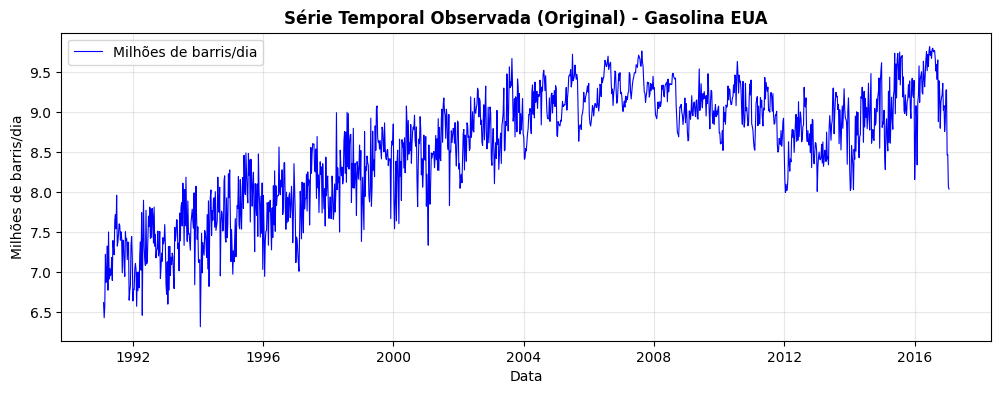

In [4]:
# Visualização da série
plt.figure(figsize=(12, 4))
plt.plot(df, label='Milhões de barris/dia', color='blue', linewidth=0.8)
plt.title('Série Temporal Observada (Original) - Gasolina EUA', fontweight = "bold")
plt.xlabel('Data')
plt.ylabel('Milhões de barris/dia')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()


## <font color = Blue> **Parte 1 - Divisão ($split$) da série temporal**


- **Defina e justifique o horizonte `h` de predição**.
- Um horizonte múltiplo do período sazonal `m` é conveniente;
- Reserve os **últimos `h` semanas para teste**, utilizando os dados anteriores como treino e validação;


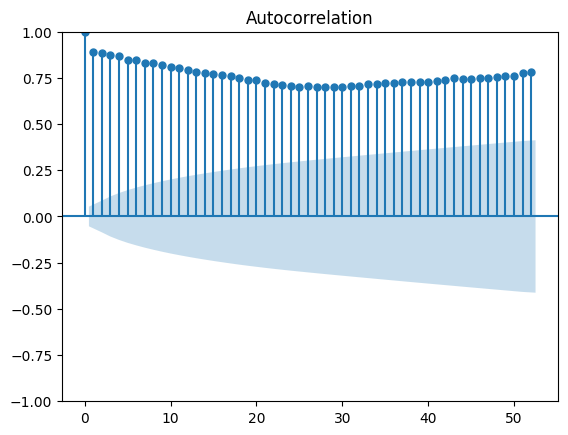

In [5]:
plot_acf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

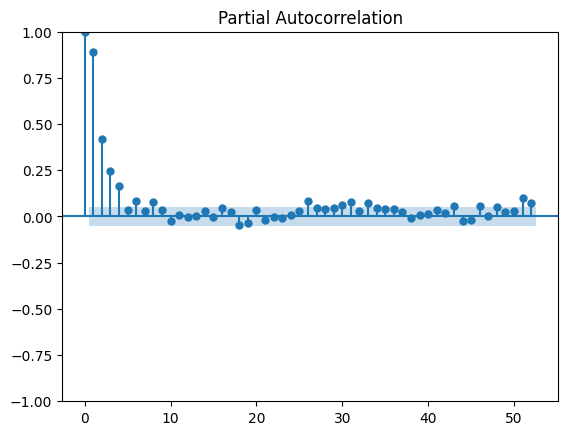

In [6]:
plot_pacf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

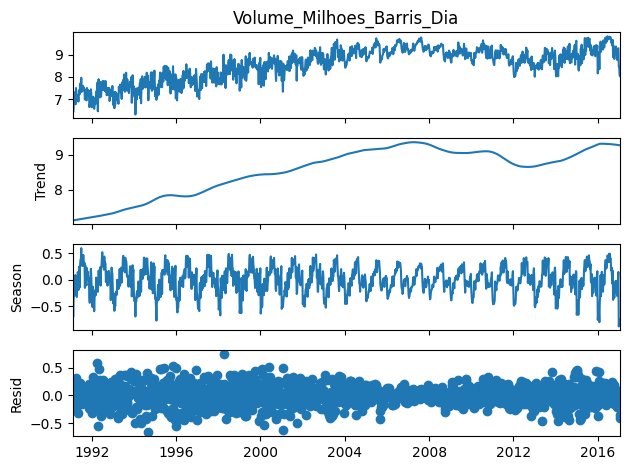

In [7]:
stl = STL(df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

**Escolha do período sazonal `m` e do horizonte `h`**

- O ACF mostra picos que se repetem perto do lag 52 e a decomposição STL apresenta um componente sazonal anual bem definido. Por isso, usamos **m = 52** (semanas em um ano).
- Escolhemos **h = 52 semanas (1 ano)**, porque:
  - é múltiplo do período sazonal (h = m), então o teste cobre **um ciclo sazonal completo** (pico de verão e baixa de inverno);
  - um horizonte de 1 ano é útil na prática para planejar oferta e estoques de combustível;
  - como a série tem 1355 semanas, separar 52 para teste ainda deixa um treino longo (1303 semanas) para a validação cruzada.

In [8]:
m = 52   # Período sazonal (semanas em um ano)
h = 52   # Horizonte de predição: 1 ciclo sazonal completo

train_df = df.iloc[:-h]
test_df = df.iloc[-h:]

print(f"Total: {len(df)} semanas")
print(f"Treino: {len(train_df)} semanas ({train_df.index.min().date()} a {train_df.index.max().date()})")
print(f"Teste: {len(test_df)} semanas ({test_df.index.min().date()} a {test_df.index.max().date()})")

Total: 1355 semanas
Treino: 1303 semanas (1991-02-08 a 2016-01-22)
Teste: 52 semanas (2016-01-29 a 2017-01-20)


- **Plot o split da série, isto é, os conjuntos de treino e teste**

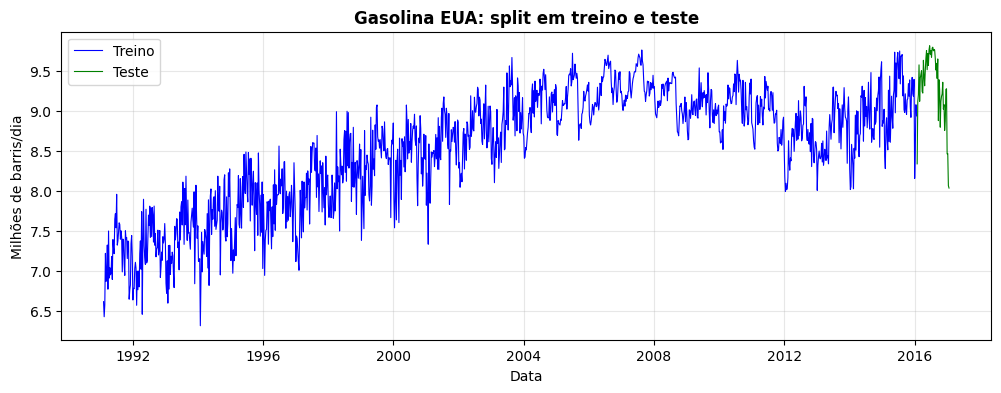

In [9]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df.Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste", color="green", linewidth=0.8)
plt.title("Gasolina EUA: split em treino e teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## <font color = Blue> **Parte 2 - Tratamento da Série (Detecção e tratamento de anomalias)**


Verifique se o conjunto de treino precisa de algum tratamento. Deixe clara sua escolha, explicando o motivo.
- **Obs:** a escolha pode ser "nada a ajustar".



In [10]:
train_df.head()

,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


In [11]:
train_df.isnull().sum()

,0
Volume_Milhoes_Barris_Dia,0


In [12]:
train_df.describe()

,Volume_Milhoes_Barris_Dia
count,1303.000000
mean,8.523015
std,0.724014
min,6.321000
25%,8.016500
50%,8.684000
75%,9.090000
max,9.762000


In [13]:
serie_treino = train_df.Volume_Milhoes_Barris_Dia

print("Valores nulos:", serie_treino.isna().sum())
print("Datas duplicadas:", serie_treino.index.duplicated().sum())

# Verifica se todas as datas estão espaçadas de exatamente 7 dias
intervalos = serie_treino.index.to_series().diff().dropna()
print("Intervalos entre datas:", intervalos.value_counts().to_dict())

serie_treino.describe()

Valores nulos: 0
Datas duplicadas: 0
Intervalos entre datas: {Timedelta('7 days 00:00:00'): 1302}


,Volume_Milhoes_Barris_Dia
count,1303.000000
mean,8.523015
std,0.724014
min,6.321000
25%,8.016500
50%,8.684000
75%,9.090000
max,9.762000


Pontos com |resíduo| > 3 desvios-padrão: 7 de 1303 (0.54%)
Data
1992-04-10    0.585649
1992-04-17   -0.555539
1994-09-09   -0.667693
1995-12-29   -0.551104
1998-04-03    0.747060
2000-03-03   -0.541216
2001-01-26   -0.629865
Name: resid, dtype: float64


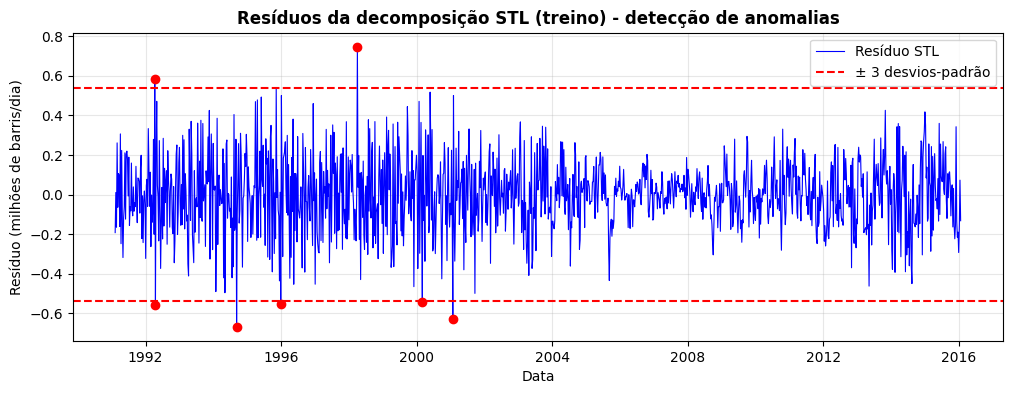

In [14]:
# Detecção de anomalias: resíduos da decomposição STL do treino
stl_treino = STL(serie_treino, period=m).fit()
residuo = stl_treino.resid

limite = 3 * residuo.std()   # regra dos 3 desvios-padrão
outliers = residuo[abs(residuo) > limite]

print(f"Pontos com |resíduo| > 3 desvios-padrão: {len(outliers)} de {len(residuo)} ({100 * len(outliers) / len(residuo):.2f}%)")
print(outliers)

plt.figure(figsize=(12, 4))
plt.plot(residuo, color="blue", linewidth=0.8, label="Resíduo STL")
plt.axhline(limite, color="red", linestyle="--", label="± 3 desvios-padrão")
plt.axhline(-limite, color="red", linestyle="--")
plt.scatter(outliers.index, outliers, color="red", zorder=3)
plt.title("Resíduos da decomposição STL (treino) - detecção de anomalias", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Resíduo (milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Decisão: nada a ajustar.**

- Não há valores nulos nem datas duplicadas.
- Todas as datas estão espaçadas exatamente 7 dias, ou seja, o calendário semanal está completo e regular.
- Os valores (entre 6,3 e 9,8 milhões de barris/dia) são plausíveis para a série.
- Nos resíduos do STL, apenas **7 pontos (cerca de 0,5% do treino)** passam de 3 desvios-padrão. São semanas isoladas, espalhadas ao longo da série, e alguns aparecem em pares que se compensam (ex.: alta em 10/04/1992 e queda em 17/04/1992). Isso é típico da oscilação das estimativas semanais da EIA, e não um erro de registro.
- Como esses pontos representam variações reais da oferta, removê-los ou suavizá-los apagaria informação legítima. Por isso, **mantivemos a série original**.

## <font color = Blue> **Parte 3 - Análise e Diagnóstico**
- Faça plot de um período curto do conjunto de treino (trecho ampliado) para identificar visualmente sazonalidade;
- Faça análises de autocorrelação, estacionariedade e sazonalidade utilizando o conjunto de treino.


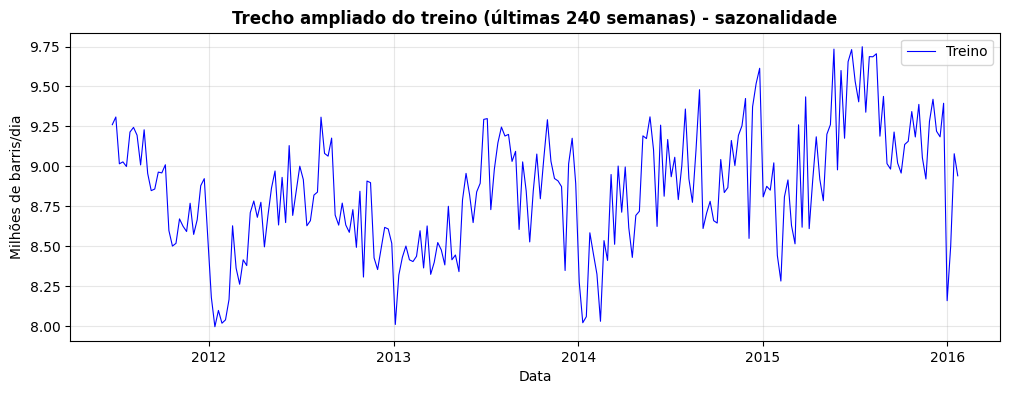

In [15]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df[-240:].Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.title("Trecho ampliado do treino (últimas 240 semanas) - sazonalidade", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

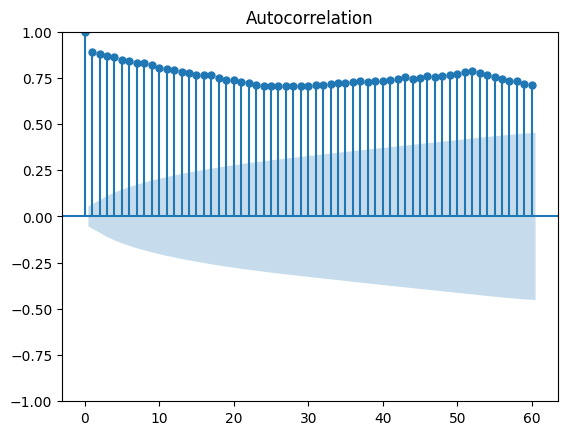

In [16]:
plot_acf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

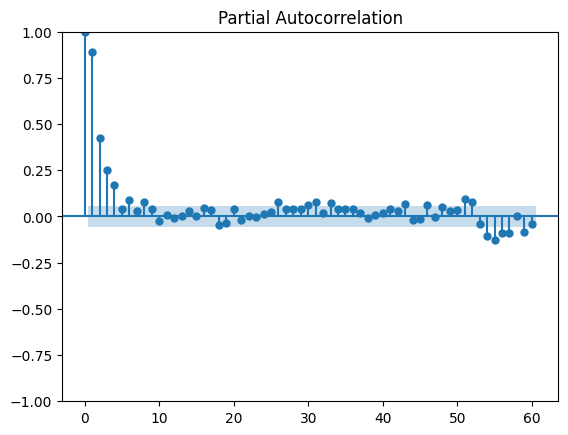

In [17]:
plot_pacf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

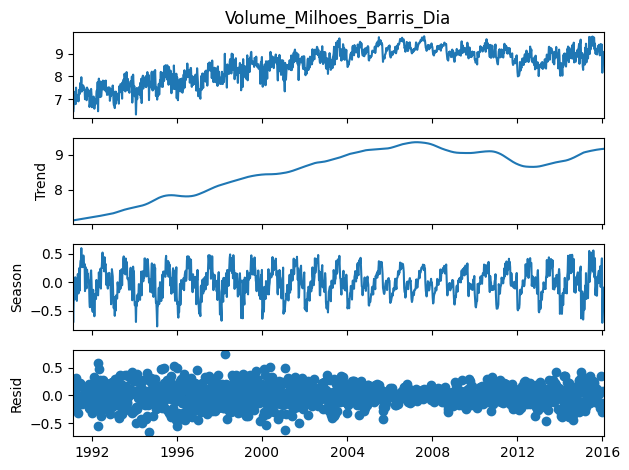

In [18]:
stl = STL(train_df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

In [19]:
adfuller(train_df.Volume_Milhoes_Barris_Dia.values, result_object=True)

ADFullerResult
ADF Statistic: -2.76068
P-value: 0.06411
Used Lag: 8
Nobs: 1294
Critical Values: {'1%': np.float64(-3.4354136163971782), '5%': np.float64(-2.8637761637845895), '10%': np.float64(-2.5679605492954045)}

**Interpretação da análise**

- **Trecho ampliado:** há um padrão que se repete todo ano, com picos no verão dos EUA (temporada de viagens) e quedas no inverno, o que confirma a sazonalidade anual.
- **ACF:** as autocorrelações são altas e caem bem devagar, o que indica **tendência**, ou seja, a série **não é estacionária**. Também aparece um pico perto do lag 52, que reforça a sazonalidade anual.
- **PACF:** o lag 1 é o mais forte, com contribuições menores nos lags seguintes e perto do lag 52.
- **STL:** a tendência sobe até por volta de 2007, recua um pouco e depois se estabiliza. O componente sazonal tem amplitude praticamente constante, o que sugere **sazonalidade aditiva**.
- **Teste ADF:** estatística = -2,76 e p-valor = 0,064. Como o p-valor é maior que 0,05, **não rejeitamos a hipótese de raiz unitária**, ou seja, a série não é estacionária a 5%. Isso justifica usar uma diferença (d = 1) no SARIMA. A primeira diferença, feita no início da Parte 4, remove a tendência.

## <font color = Blue> **Parte 4 - Treinamento e seleção do modelo**

- Compare **ETSModel, ARIMA, SARIMA, árvore de decisão, Prophet e LSTM**, *justificando eventual não aplicação*;
- Para seleção do modelo e seus hiperparâmetros, utilize **Cross Validation Temporal exclusivamente dentro do conjunto de treino**, com as mesmas janelas para todos os candidatos e blocos de validação de comprimento **`h`**;
- Selecione pelo **RMSE médio das janelas de validação**, calculado na escala original (milhões de barris por dia);
- Todos os modelos devem prever os **`h` períodos a partir da mesma origem**, sem utilizar valores reais do bloco previsto. Para árvore de decisão e LSTM, explicite a estratégia de previsão (recursiva, direta ou de múltiplas saídas).


In [20]:
dif1 = train_df.Volume_Milhoes_Barris_Dia.diff(1).dropna()
dif1.head()

,Volume_Milhoes_Barris_Dia
Data,
1991-02-15,-0.188
1991-02-22,0.149
1991-03-01,0.642
1991-03-08,-0.349
1991-03-15,0.072


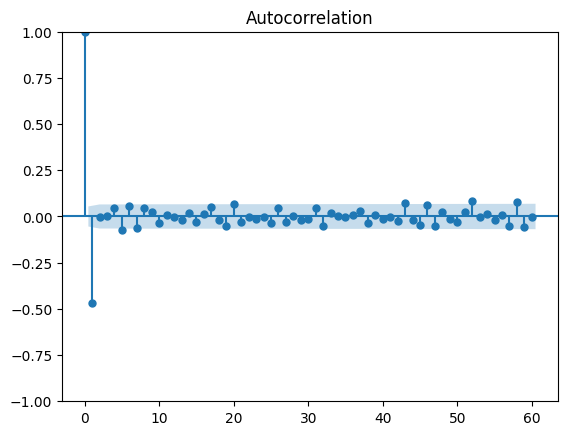

In [21]:
plot_acf(dif1, lags=60)
plt.show()

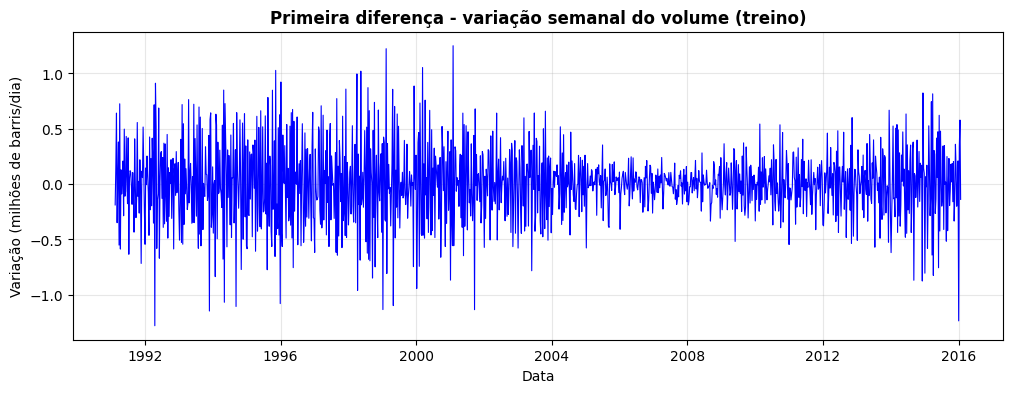

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(dif1, color="blue", linewidth=0.8)
plt.title("Primeira diferença - variação semanal do volume (treino)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Variação (milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.show()

In [23]:
n_janelas = 5 # número de janelas
n_inicial = len(train_df) - h * n_janelas
window_inicial = train_df.iloc[:n_inicial]
print(f"Treino: {len(train_df)} semanas | Teste: {len(test_df)} semanas")
print(f"Treino inicial da CV: {n_inicial} semanas")

Treino: 1303 semanas | Teste: 52 semanas
Treino inicial da CV: 1043 semanas


In [24]:
error_opts = ['add', 'mul']
trend_opts = [None, 'add', 'mul']
seasonal_opts = [None, 'add', 'mul']

min_train_size = n_inicial
horizon = h
step_size = h

cv_starts = list(range(min_train_size, len(train_df) - horizon + 1, step_size))

best_cv_rmse = float('inf')
best_cv_model_name = None
best_cv_cfg = None

# Executar Grid Search avaliado via Cross Validation
for e in error_opts:
    for t in trend_opts:
        for s in seasonal_opts:
            rmses = []
            # Estrutura do laço de janelas em expansão
            for start in cv_starts:
                cv_train = train_df.iloc[:start]
                cv_val = train_df.iloc[start:start+horizon]

                try:
                    model_cv = ETSModel(cv_train['Volume_Milhoes_Barris_Dia'], error=e, trend=t, seasonal=s, seasonal_periods=m)
                    fit_cv = model_cv.fit(disp=False)
                    pred_cv = fit_cv.forecast(steps=horizon)

                    rmse = root_mean_squared_error(cv_val['Volume_Milhoes_Barris_Dia'], pred_cv)
                    rmses.append(rmse)
                except:
                    continue

            if len(rmses) == len(cv_starts) and np.isfinite(rmses).all():
                mean_rmse = np.mean(rmses)
                if mean_rmse < best_cv_rmse:
                    best_cv_rmse = mean_rmse
                    best_cv_model_name = f"ETS({e[0].upper()},{'N' if t is None else t[0].upper()},{'N' if s is None else s[0].upper()})"
                    best_cv_cfg = (e, t, s)

print(f"Melhor modelo por CV: {best_cv_model_name} com RMSE Médio Validado = {best_cv_rmse:.4f}")

Melhor modelo por CV: ETS(A,N,A) com RMSE Médio Validado = 0.3025


### SARIMA

**Por que SARIMA e não ARIMA?** O ARIMA não sazonal não foi aplicado porque a série tem sazonalidade anual evidente (picos no ACF perto do lag 52 e componente sazonal claro no STL). O ARIMA não consegue modelar esse padrão. Por isso, usamos o SARIMA, que tem a mesma parte não sazonal do ARIMA (p, d, q) e acrescenta os termos sazonais (P, D, Q) com m = 52.

**Seleção dos hiperparâmetros:** usamos o `auto_arima` só para sugerir boas ordens candidatas (menor AIC). A escolha final entre elas é feita pela **mesma validação cruzada** usada nos outros modelos.

In [25]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 7.3 MB/s  0:00:00


In [26]:
from pmdarima import auto_arima

In [27]:
# Reduzindo os dados de treino inicial para as últimas 520 semanas
# Assim, o auto_arima não acessa os blocos de validação da CV
train_df_reduzido = window_inicial.iloc[-520:]

print(f"Ajustando auto_arima com dados reduzidos do treino inicial: {len(train_df_reduzido)} semanas.")
print(f"Período utilizado: {train_df_reduzido.index.min().date()} a {train_df_reduzido.index.max().date()}")

# Ajuste do auto_arima otimizado com limites conservadores
model = auto_arima(
    train_df_reduzido.Volume_Milhoes_Barris_Dia,
    start_p=1, start_q=1,
    max_p=2, max_q=2,
    m=m,
    seasonal=True,
    start_P=1, start_Q=0,
    max_P=1, max_Q=1,
    max_D=1,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
    n_jobs=1
)

print("Melhores parâmetros encontrados:", model.order, model.seasonal_order)


Ajustando auto_arima com dados reduzidos do treino inicial: 520 semanas.
Período utilizado: 2001-02-16 a 2011-01-28
Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,0)[52] intercept   : AIC=-214.592, Time=15.55 sec
 ARIMA(0,1,0)(0,0,0)[52] intercept   : AIC=-64.643, Time=0.28 sec
 ARIMA(1,1,0)(1,0,0)[52] intercept   : AIC=-147.977, Time=7.48 sec
 ARIMA(0,1,1)(0,0,1)[52] intercept   : AIC=-198.008, Time=4.19 sec
 ARIMA(0,1,0)(0,0,0)[52]             : AIC=-66.625, Time=0.10 sec
 ARIMA(1,1,1)(0,0,0)[52] intercept   : AIC=-170.204, Time=0.18 sec
 ARIMA(1,1,1)(1,0,1)[52] intercept   : AIC=inf, Time=13.09 sec
 ARIMA(1,1,1)(0,0,1)[52] intercept   : AIC=-201.464, Time=6.83 sec
 ARIMA(0,1,1)(1,0,0)[52] intercept   : AIC=-211.998, Time=3.07 sec
 ARIMA(2,1,1)(1,0,0)[52] intercept   : AIC=-213.699, Time=9.83 sec
 ARIMA(1,1,2)(1,0,0)[52] intercept   : AIC=-214.903, Time=7.87 sec
 ARIMA(1,1,2)(0,0,0)[52] intercept   : AIC=-169.063, Time=0.40 sec
 ARIMA(1,1,2)(1,0,1)[52] intercept   : AIC

In [29]:
# Ordens candidatas selecionadas pelo auto_arima (menores AIC)
# A escolha final é feita pela validação cruzada, usando as mesmas janelas dos outros modelos

candidatos = [(0, 1, 2), (1, 1, 2), (1, 1, 1)]
ordem_sazonal_auto = (1, 0, 0, m)

resultados = []

for ordem in candidatos:
    rmse_windows = []

    for step in range(n_janelas):
        fim = n_inicial + h * step

        window = train_df.iloc[:fim]
        val_set = train_df.iloc[fim:fim + h]

        # Ajustando o modelo SARIMA com a ordem candidata
        ajuste = SARIMAX(
            window.Volume_Milhoes_Barris_Dia,
            order=ordem,
            seasonal_order=ordem_sazonal_auto,
            trend="c"
        ).fit(maxiter=200, disp=False)

        if not ajuste.mle_retvals["converged"]:
            print(f"SARIMA{ordem}{ordem_sazonal_auto} - janela {step + 1}: não convergiu")
            break

        previsao = ajuste.forecast(steps=h)

        rmse_windows.append(
            root_mean_squared_error(
                val_set.Volume_Milhoes_Barris_Dia,
                previsao
            )
        )

    # Só aceitamos a ordem se ela convergiu em todas as janelas
    erro_medio = np.mean(rmse_windows) if len(rmse_windows) == n_janelas else np.nan

    resultados.append({
        "order": ordem,
        "RMSE": erro_medio
    })

Tabela_SARIMA = pd.DataFrame(resultados).sort_values("RMSE")

Tabela_SARIMA


,order,RMSE
1,"(1, 1, 2)",0.370909
2,"(1, 1, 1)",0.373998
0,"(0, 1, 2)",0.374182


In [30]:
melhor_sarima = Tabela_SARIMA.iloc[0]
ordem_auto = melhor_sarima["order"]
erro = melhor_sarima["RMSE"]
print(f"Modelo escolhido pela CV: SARIMA{ordem_auto}{ordem_sazonal_auto} com drift")
print(f"RMSE médio na CV: {erro:.4f}")

Modelo escolhido pela CV: SARIMA(1, 1, 2)(1, 0, 0, 52) com drift
RMSE médio na CV: 0.3709


- **Conclusão do SARIMA**

O melhor modelo SARIMA pela validação cruzada é o SARIMA(1,1,2)(1,0,0)[52] com drift e RMSE médio ≈ 0,3709. As três ordens candidatas ficaram muito próximas.

### Árvore de Decisão

**Estratégia de previsão: recursiva.** A árvore é treinada para prever **1 semana à frente**, usando como entrada os `p` valores anteriores (lags) e o mês. Para prever as `h` semanas, a previsão de cada semana entra como lag na previsão da semana seguinte. Assim, nenhum valor real do bloco previsto é usado.

In [31]:
profundidade_min = 1
profundidade_max = 10
resultados = []

for p in [1, 2, 4]:
    for i in range(profundidade_min, profundidade_max + 1):
        rmse_windows = []
        for step in range(n_janelas):
            fim = n_inicial + h * step
            window = train_df.iloc[:fim]
            val_set = train_df.iloc[fim:fim + h]

            # Preparando a série (lags)
            df_arvore = window[['Volume_Milhoes_Barris_Dia']].copy()
            for k in range(p):
                df_arvore[f'X_{k+1}'] = df_arvore.Volume_Milhoes_Barris_Dia.shift(k+1)
            df_arvore['month'] = df_arvore.index.month
            df_arvore.dropna(axis=0, inplace=True)

            # Variáveis preditoras (X: input) e variável alvo (y: output)
            X = df_arvore.drop('Volume_Milhoes_Barris_Dia', axis=1)
            y = df_arvore.Volume_Milhoes_Barris_Dia

            model = DecisionTreeRegressor(random_state=42, max_depth=i).fit(X, y)

            # Método recursivo para fazer predição para o horizonte h
            lag_vars = [f"X_{k+1}" for k in range(p)]
            lags = list(window.Volume_Milhoes_Barris_Dia.iloc[-p:][::-1])  # últimos valores observados (X_1 = mais recente)
            future_preds = []

            for data in val_set.index:
                # Cria o próximo vetor de entrada
                x_next = pd.DataFrame({var: [lags[k]] for k, var in enumerate(lag_vars)})
                x_next["month"] = [data.month]

                # Faz a previsão
                y_pred = model.predict(x_next)[0]
                future_preds.append(y_pred)

                # Atualiza os lags (shift: o mais recente entra na frente)
                lags = [y_pred] + lags[:-1]

            rmse_windows.append(root_mean_squared_error(val_set.Volume_Milhoes_Barris_Dia, future_preds))

        resultados.append({"p": p, "max_depth": i, "RMSE": np.mean(rmse_windows)})

Tabela_Arvore = pd.DataFrame(resultados).sort_values("RMSE")
Tabela_Arvore.head(10)

,p,max_depth,RMSE
27,4,8,0.450656
26,4,7,0.455791
19,2,10,0.456726
1,1,2,0.458083
24,4,5,0.478763
0,1,1,0.490274
23,4,4,0.506594
29,4,10,0.508588
15,2,6,0.508883
21,4,2,0.523046


In [32]:
melhor_arvore = Tabela_Arvore.iloc[0]
print(f"Modelo escolhido pela CV: p = {int(melhor_arvore['p'])}, max_depth = {int(melhor_arvore['max_depth'])}")
print(f"RMSE médio na CV: {melhor_arvore['RMSE']:.4f}")

Modelo escolhido pela CV: p = 4, max_depth = 8
RMSE médio na CV: 0.4507


### Prophet

In [33]:
# Criando um df com as colunas ds e y
df_prophet = pd.DataFrame({"ds": train_df.index, "y": train_df.Volume_Milhoes_Barris_Dia.values})
df_prophet.head()

,ds,y
0,1991-02-08,6.621
1,1991-02-15,6.433
2,1991-02-22,6.582
3,1991-03-01,7.224
4,1991-03-08,6.875


In [34]:
resultados = []

for modo in ["additive", "multiplicative"]:
    rmse_windows = []
    for step in range(n_janelas):
        fim = n_inicial + h * step
        Train_set = df_prophet[:fim]
        Test_set = df_prophet[fim:fim + h]

        model = Prophet(seasonality_mode=modo, daily_seasonality=False, weekly_seasonality=False, yearly_seasonality=True ).fit(Train_set)

        # Para predição no Prophet, é necessário passar um DataFrame com as datas desejadas
        y_pred = model.predict(Test_set)

        MSE = ((Test_set.y.values - y_pred.yhat.values)**2).mean()
        RMSE = np.sqrt(MSE)
        rmse_windows.append(RMSE)

    resultados.append({"seasonality_mode": modo, "RMSE": np.mean(rmse_windows)})

Tabela_Prophet = pd.DataFrame(resultados).sort_values("RMSE")
Tabela_Prophet

,seasonality_mode,RMSE
1,multiplicative,0.350851
0,additive,0.353179


In [35]:
melhor_prophet = Tabela_Prophet.iloc[0]
print(f"Modelo escolhido pela CV: seasonality_mode = '{melhor_prophet['seasonality_mode']}'")
print(f"RMSE médio na CV: {melhor_prophet['RMSE']:.4f}")

Modelo escolhido pela CV: seasonality_mode = 'multiplicative'
RMSE médio na CV: 0.3509


### LSTM

**Estratégia de previsão: recursiva.**
1. Aplicamos a diferença sazonal (lag 52) e normalizamos com `MinMaxScaler`, ajustado apenas na janela de treino.
2. A rede aprende a prever 1 semana à frente a partir das últimas `window_size` semanas.
3. Para prever as h semanas, cada previsão é colocada no fim da janela e usada para prever a semana seguinte.
4. No final, desfazemos a normalização e a diferença sazonal (usando o último ano observado do treino) e calculamos o RMSE na escala original.

Fixamos a semente aleatória (`set_random_seed`) para que os resultados sejam reprodutíveis.

In [36]:
periodo_sazonal = m

# Função para criar janelas
def create_dataset(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])
    return np.array(X), np.array(y)


def reverter_diferenca_sazonal(diferencas_previstas, serie_original, periodo):
    # Os primeiros valores de referência vêm do último ciclo observado.
    niveis = serie_original.iloc[-periodo:].to_list()
    for i, diferenca in enumerate(diferencas_previstas):
        niveis.append(niveis[i] + diferenca)
    return np.array(niveis[periodo:])

In [37]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)   # resultados reprodutíveis

resultados = []

for window_size in [4, 12, 52]:
    for units in [16, 32]:
        rmse_windows = []
        for step in range(n_janelas):
            fim = n_inicial + h * step
            window = train_df.iloc[:fim]
            val_set = train_df.iloc[fim:fim + h]

            # Diferença sazonal e escalonamento
            serie_diff = window.Volume_Milhoes_Barris_Dia.diff(periodo_sazonal).dropna()
            diferencas = serie_diff.to_numpy().reshape(-1, 1)
            scaler = MinMaxScaler(feature_range=(0, 1))
            scaler.fit(diferencas)
            serie_scaled = scaler.transform(diferencas)

            # Criação das janelas deslizantes e formato 3D para a LSTM
            X, y = create_dataset(serie_scaled, window_size)
            X = X.reshape((X.shape[0], X.shape[1], 1))

            model = Sequential([Input(shape=(window_size, 1)),LSTM(units= units, activation='tanh'),Dense(1)])
            model.compile(optimizer='adam', loss='mse')
            history = model.fit(X, y, epochs=20, batch_size= 16, verbose=0)

            # Previsão recursiva
            janela = serie_scaled[-window_size:].copy().reshape(1, window_size, 1)
            forecast_scaled = []

            for _ in range(h):
                proxima_diff_scaled = model.predict(janela, verbose=0)
                forecast_scaled.append(proxima_diff_scaled[0, 0])
                janela = np.append(janela[:, 1:, :], proxima_diff_scaled.reshape(1, 1, 1), axis=1)

            forecast_scaled = np.array(forecast_scaled).reshape(-1, 1)
            forecast_diff = scaler.inverse_transform(forecast_scaled).ravel()
            forecast = reverter_diferenca_sazonal(forecast_diff, window.Volume_Milhoes_Barris_Dia, periodo_sazonal)

            rmse_windows.append(root_mean_squared_error(val_set.Volume_Milhoes_Barris_Dia, forecast))

        resultados.append({"window_size": window_size, "units": units, "RMSE": np.mean(rmse_windows)})

Tabela_LSTM = pd.DataFrame(resultados).sort_values("RMSE")
Tabela_LSTM

,window_size,units,RMSE
4,52,16,0.356397
5,52,32,0.362020
2,12,16,0.373148
3,12,32,0.377325
0,4,16,0.397727
1,4,32,0.406504


In [38]:
melhor_lstm = Tabela_LSTM.iloc[0]
print(f"Modelo escolhido pela CV: window_size = {int(melhor_lstm['window_size'])}, units = {int(melhor_lstm['units'])}")
print(f"RMSE médio na CV: {melhor_lstm['RMSE']:.4f}")

Modelo escolhido pela CV: window_size = 52, units = 16
RMSE médio na CV: 0.3564


In [39]:
# Comparação final de todos os modelos pelo RMSE médio da validação cruzada
Tabela_CV = pd.DataFrame({
    "Modelo": [
        best_cv_model_name,
        f"SARIMA{ordem_auto}{ordem_sazonal_auto} com drift",
        f"Árvore de Decisão (p={int(melhor_arvore['p'])}, max_depth={int(melhor_arvore['max_depth'])})",
        f"Prophet ({melhor_prophet['seasonality_mode']})",
        f"LSTM (window_size={int(melhor_lstm['window_size'])}, units={int(melhor_lstm['units'])})",
    ],
    "RMSE médio CV": [best_cv_rmse, erro, melhor_arvore['RMSE'], melhor_prophet['RMSE'], melhor_lstm['RMSE']],
})

Tabela_CV = Tabela_CV.sort_values("RMSE médio CV").reset_index(drop=True)
Tabela_CV

,Modelo,RMSE médio CV
0,"ETS(A,N,A)",0.302519
1,Prophet (multiplicative),0.350851
2,"LSTM (window_size=52, units=16)",0.356397
3,"SARIMA(1, 1, 2)(1, 0, 0, 52) com drift",0.370909
4,"Árvore de Decisão (p=4, max_depth=8)",0.450656


**Modelo escolhido: ETS(A,N,A)**

O ETS(A,N,A) teve o menor RMSE médio nas 5 janelas de validação (≈ 0,3025 milhões de barris/dia), como mostra a tabela acima. Ele tem erro aditivo, nenhuma tendência e sazonalidade aditiva (m = 52). Isso combina com a análise da Parte 3: no período mais recente a tendência fica praticamente estável, e a sazonalidade tem amplitude constante.

O ARIMA não sazonal não foi aplicado (ver justificativa na seção do SARIMA).

## <font color = Blue> **Parte 5 - Avaliação do modelo no conjunto de teste**

- **Treine o modelo escolhido em todo o conjunto de treino**;
- **Avalie o modelo (escolhido na Parte 4) no conjunto de teste**. Para isso:
  - Faça a predição dos **`h` semanas**, sem utilizar valores reais do teste para atualizar as previsões, e compare com os dados observados;
  - Inclua **intervalo de previsão de 95% quando o modelo oferecer esse recurso**; caso contrário, justifique sua ausência;
  - Calcule o **RMSE no conjunto de teste, na escala original**;
- Não utilize o resultado do teste para trocar ou reajustar a configuração do modelo escolhido.


RMSE do modelo escolhido ETS(A,N,A) no conjunto de teste: 0.3292


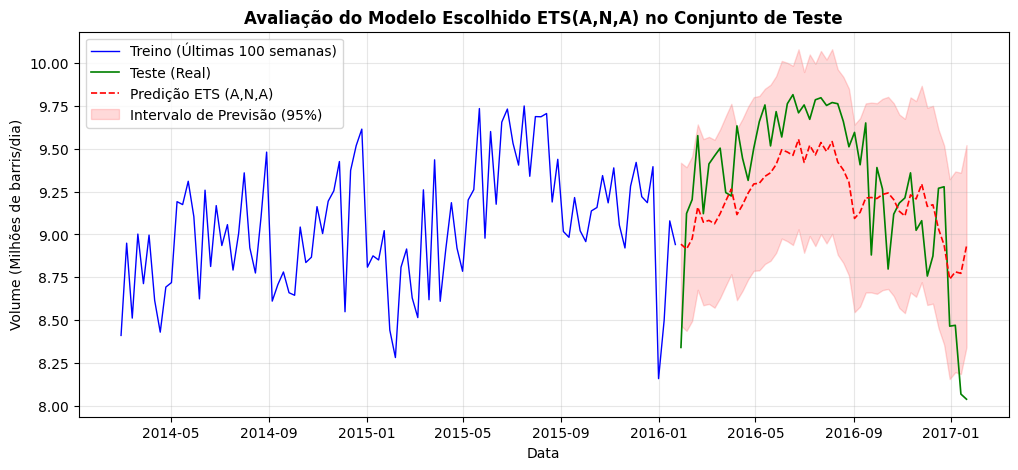

In [40]:
# 1. Ajustar o modelo escolhido em todo o conjunto de treino
model_final = ETSModel(
    train_df['Volume_Milhoes_Barris_Dia'],
    error='add',
    trend=None,
    seasonal='add',
    seasonal_periods=m
)
fit_final = model_final.fit(disp=False)

# 2. Gerar previsões para o horizonte de teste h = 52 com intervalo de confiança (95%)
forecast_res = fit_final.get_prediction(start=test_df.index[0], end=test_df.index[-1])
preds_teste = forecast_res.predicted_mean
conf_int_teste = forecast_res.summary_frame(alpha=0.05)

# 3. Calcular o RMSE no conjunto de teste (escala original)
rmse_teste = root_mean_squared_error(test_df['Volume_Milhoes_Barris_Dia'], preds_teste)
print(f"RMSE do modelo escolhido ETS(A,N,A) no conjunto de teste: {rmse_teste:.4f}")

# 4. Plotar os resultados
plt.figure(figsize=(12, 5))
plt.plot(train_df['Volume_Milhoes_Barris_Dia'].iloc[-100:], label="Treino (Últimas 100 semanas)", color="blue", linewidth=1)
plt.plot(test_df['Volume_Milhoes_Barris_Dia'], label="Teste (Real)", color="green", linewidth=1.2)
plt.plot(preds_teste, label="Predição ETS (A,N,A)", color="red", linestyle="--", linewidth=1.2)
plt.fill_between(
    test_df.index,
    conf_int_teste["pi_lower"],
    conf_int_teste["pi_upper"],
    color="red",
    alpha=0.15,
    label="Intervalo de Previsão (95%)"
)
plt.title("Avaliação do Modelo Escolhido ETS(A,N,A) no Conjunto de Teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Volume (Milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.legend(loc="upper left")
plt.show()

**Avaliação no teste**

- O RMSE no teste foi **≈ 0,329 milhões de barris/dia**, próximo do RMSE médio da validação cruzada (≈ 0,303). Isso indica que o modelo **generaliza bem** e que a CV deu uma boa estimativa do erro fora da amostra.
- A previsão acompanha o padrão sazonal observado, e os valores reais ficam, em sua maioria, dentro do **intervalo de previsão de 95%**.
- As previsões foram geradas a partir do fim do treino, **sem usar valores reais do teste**.

## <font color = Blue> **Parte 6 - Predição (forecast)**

- **Após concluir a avaliação, treine o modelo escolhido na série completa (treino + teste)**, mantendo a configuração selecionada;
- **Faça a predição para os próximos `h` semanas**, incluindo plot e intervalo de previsão de 95% quando disponível; caso contrário, justifique sua ausência.


,mean,pi_lower,pi_upper
2017-01-27,8.713505,8.235784,9.191226
2017-02-03,8.716181,8.235340,9.197021
2017-02-10,8.777495,8.293555,9.261434
2017-02-17,8.969155,8.482136,9.456175
2017-02-24,8.867284,8.377204,9.357364
2017-03-03,8.888606,8.395485,9.381727
2017-03-10,8.871688,8.375544,9.367831
2017-03-17,8.930379,8.431230,9.429527
2017-03-24,8.991032,8.488897,9.493167
2017-03-31,9.057928,8.552825,9.563032


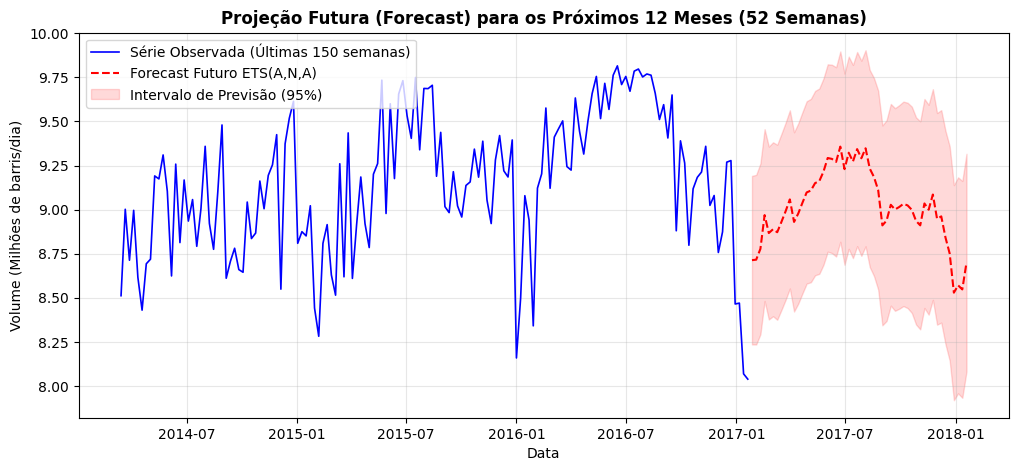

In [41]:
# 1. Ajustar o modelo escolhido ETS(A,N,A) em todo o conjunto de dados (Treino + Teste)
model_prod = ETSModel(
    df['Volume_Milhoes_Barris_Dia'],
    error='add',
    trend=None,
    seasonal='add',
    seasonal_periods=m
)
fit_prod = model_prod.fit(disp=False)

# Definir as datas de início e fim do horizonte de previsão futura
# Como a série termina em 2017-01-20, as previsões cobrirão as próximas 52 semanas
start_date = df.index[-1] + pd.Timedelta(weeks=1)
end_date = df.index[-1] + pd.Timedelta(weeks=h)

# 2. Gerar previsões futuras e intervalos de predição de 95%
forecast_prod_res = fit_prod.get_prediction(start=start_date, end=end_date)
preds_futuras = forecast_prod_res.predicted_mean
conf_int_futuras = forecast_prod_res.summary_frame(alpha=0.05)

# Exibir as primeiras projeções futuras geradas
display(conf_int_futuras.head(10))

# 3. Plotar a série histórica recente e as predições futuras
plt.figure(figsize=(12, 5))
plt.plot(df['Volume_Milhoes_Barris_Dia'].iloc[-150:], label="Série Observada (Últimas 150 semanas)", color="blue", linewidth=1.2)
plt.plot(preds_futuras, label="Forecast Futuro ETS(A,N,A)", color="red", linestyle="--", linewidth=1.5)
plt.fill_between(
    preds_futuras.index,
    conf_int_futuras["pi_lower"],
    conf_int_futuras["pi_upper"],
    color="red",
    alpha=0.15,
    label="Intervalo de Previsão (95%)"
)
plt.title("Projeção Futura (Forecast) para os Próximos 12 Meses (52 Semanas)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Volume (Milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.legend(loc="upper left")
plt.show()

## <font color = Blue> **Anexo - Comparação complementar no conjunto de teste**

A seleção do modelo foi feita **exclusivamente** pelo RMSE médio da validação cruzada (Parte 4). As células abaixo treinam os outros candidatos no treino completo e mostram o desempenho deles no teste **apenas como ilustração**. Esses resultados **não** foram usados para escolher ou ajustar o modelo.

### SARIMA

Treinando o modelo SARIMA(1, 1, 2)(1, 0, 0, 52)...
RMSE do modelo SARIMA(1, 1, 2) no teste: 0.5207


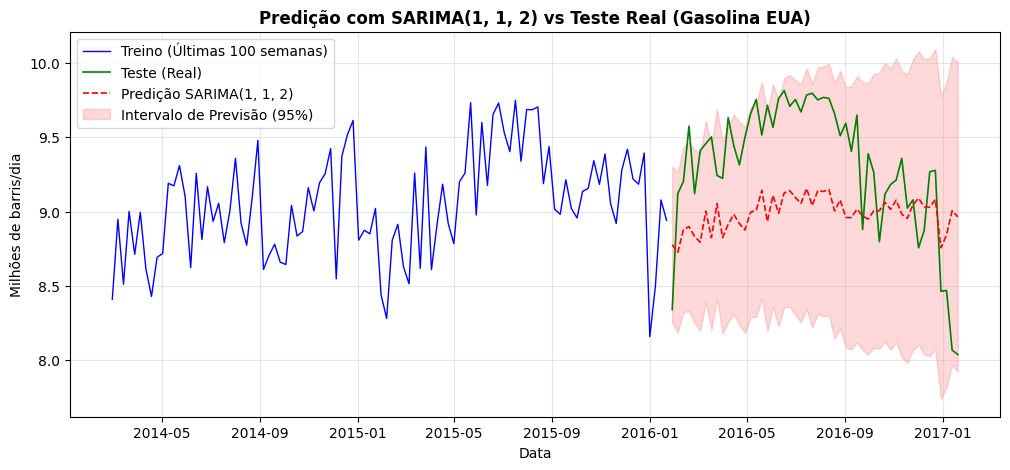

In [42]:
# Treinar o SARIMA escolhido pela CV no conjunto de treino completo
ordem_nova = ordem_auto
ordem_sazonal_nova = ordem_sazonal_auto

print(f"Treinando o modelo SARIMA{ordem_nova}{ordem_sazonal_nova}...")
model_sarima_novo = SARIMAX(
    train_df.Volume_Milhoes_Barris_Dia,
    order=ordem_nova,
    seasonal_order=ordem_sazonal_nova,
    trend="c"
)
fit_sarima_novo = model_sarima_novo.fit(maxiter=200, disp=False)

# Gerar previsões e intervalos para o teste
forecast_res_novo = fit_sarima_novo.get_forecast(steps=len(test_df))
preds_sarima = forecast_res_novo.predicted_mean
confidence_intervals = forecast_res_novo.conf_int(alpha=0.05)

rmse_sarima_test_novo = root_mean_squared_error(test_df.Volume_Milhoes_Barris_Dia, preds_sarima)
print(f"RMSE do modelo SARIMA{ordem_nova} no teste: {rmse_sarima_test_novo:.4f}")

# Plot do resultado atualizado do SARIMA
plt.figure(figsize=(12, 5))
plt.plot(train_df.Volume_Milhoes_Barris_Dia.iloc[-100:], label="Treino (Últimas 100 semanas)", color="blue", linewidth=1)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste (Real)", color="green", linewidth=1.2)
plt.plot(preds_sarima, label=f"Predição SARIMA{ordem_nova}", color="red", linestyle="--", linewidth=1.2)
plt.fill_between(
    test_df.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color="red",
    alpha=0.15,
    label="Intervalo de Previsão (95%)"
)
plt.title(f"Predição com SARIMA{ordem_nova} vs Teste Real (Gasolina EUA)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Árvore de Decisão

RMSE do modelo Árvore de Decisão no conjunto de teste: 0.9902


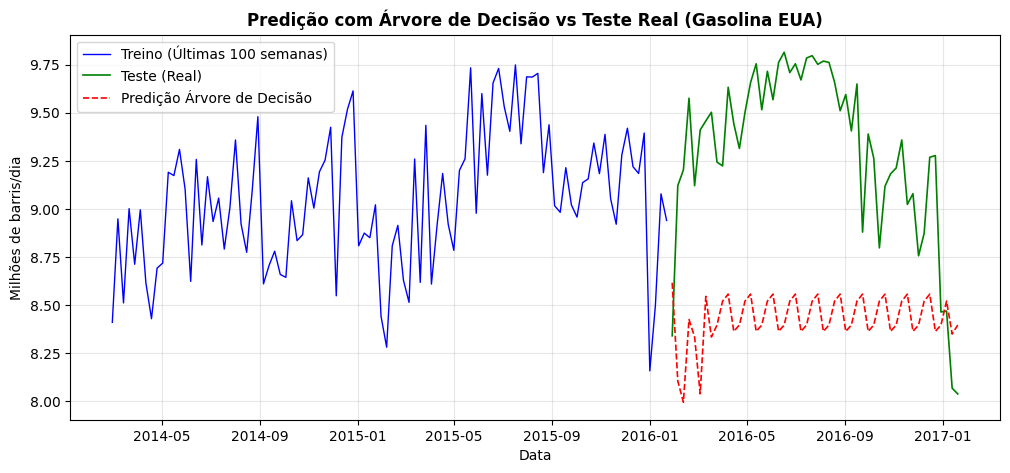

In [43]:
# Treinar o melhor modelo de Árvore de Decisão no treino completo
p_opt = int(melhor_arvore['p'])
depth_opt = int(melhor_arvore['max_depth'])

df_arvore = train_df[['Volume_Milhoes_Barris_Dia']].copy()
for k in range(p_opt):
    df_arvore[f'X_{k+1}'] = df_arvore.Volume_Milhoes_Barris_Dia.shift(k+1)
df_arvore['month'] = df_arvore.index.month
df_arvore.dropna(axis=0, inplace=True)

X_train = df_arvore.drop('Volume_Milhoes_Barris_Dia', axis=1)
y_train = df_arvore.Volume_Milhoes_Barris_Dia

model_dt = DecisionTreeRegressor(random_state=42, max_depth=depth_opt).fit(X_train, y_train)

# Predição recursiva para o conjunto de teste (h = 52)
lag_vars = [f"X_{k+1}" for k in range(p_opt)]
lags = list(train_df.Volume_Milhoes_Barris_Dia.iloc[-p_opt:][::-1])
preds_teste = []

for data in test_df.index:
    x_next = pd.DataFrame({var: [lags[k]] for k, var in enumerate(lag_vars)})
    x_next["month"] = [data.month]

    y_pred = model_dt.predict(x_next)[0]
    preds_teste.append(y_pred)

    lags = [y_pred] + lags[:-1]

# Criar série temporal para as predições
preds_series = pd.Series(preds_teste, index=test_df.index)

# Calcular RMSE no teste
rmse_dt = root_mean_squared_error(test_df.Volume_Milhoes_Barris_Dia, preds_teste)
print(f"RMSE do modelo Árvore de Decisão no conjunto de teste: {rmse_dt:.4f}")

# Plot do resultado
plt.figure(figsize=(12, 5))
plt.plot(train_df.Volume_Milhoes_Barris_Dia.iloc[-100:], label="Treino (Últimas 100 semanas)", color="blue", linewidth=1)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste (Real)", color="green", linewidth=1.2)
plt.plot(preds_series, label="Predição Árvore de Decisão", color="red", linestyle="--", linewidth=1.2)
plt.title("Predição com Árvore de Decisão vs Teste Real (Gasolina EUA)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Prophet

RMSE do modelo Prophet no conjunto de teste: 0.4683


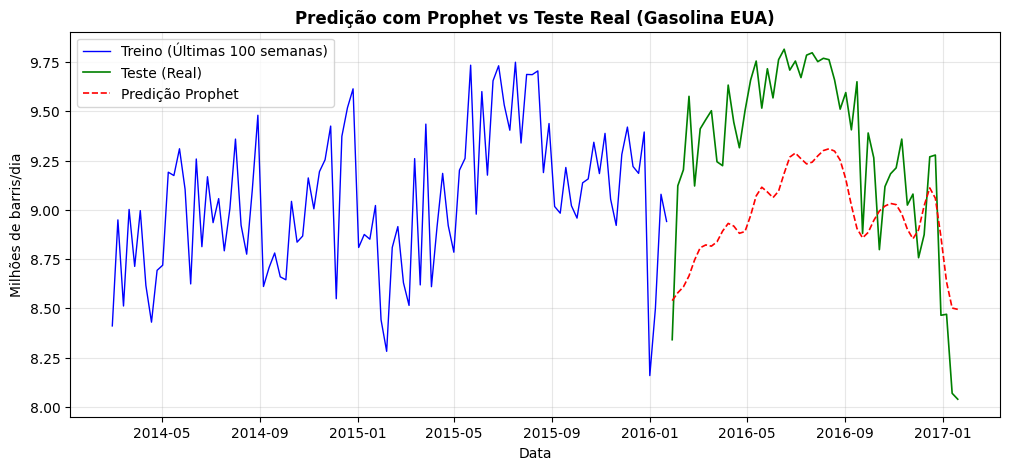

In [44]:
# Instanciar e treinar o Prophet com o melhor modo sazonal ('multiplicative')
model_prophet_final = Prophet(
    seasonality_mode='multiplicative',
    daily_seasonality=False,
    weekly_seasonality=False,
    yearly_seasonality=True
)

# Preparar os dados de treino completos para o formato do Prophet
df_prophet_train = pd.DataFrame({
    "ds": train_df.index,
    "y": train_df.Volume_Milhoes_Barris_Dia.values
})

model_prophet_final.fit(df_prophet_train)

# Gerar dataframe de datas futuras correspondentes ao conjunto de teste
future_dates = pd.DataFrame({"ds": test_df.index})
forecast_prophet = model_prophet_final.predict(future_dates)

# Criar série temporal com as predições
preds_prophet_series = pd.Series(forecast_prophet['yhat'].values, index=test_df.index)

# Calcular RMSE no conjunto de teste
rmse_prophet_test = root_mean_squared_error(test_df.Volume_Milhoes_Barris_Dia, preds_prophet_series)
print(f"RMSE do modelo Prophet no conjunto de teste: {rmse_prophet_test:.4f}")

# Plot do resultado comparando Treino, Teste e Predição
plt.figure(figsize=(12, 5))
plt.plot(train_df.Volume_Milhoes_Barris_Dia.iloc[-100:], label="Treino (Últimas 100 semanas)", color="blue", linewidth=1)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste (Real)", color="green", linewidth=1.2)
plt.plot(preds_prophet_series, label="Predição Prophet", color="red", linestyle="--", linewidth=1.2)
plt.title("Predição com Prophet vs Teste Real (Gasolina EUA)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### LSTM

RMSE do modelo LSTM no conjunto de teste: 0.4649


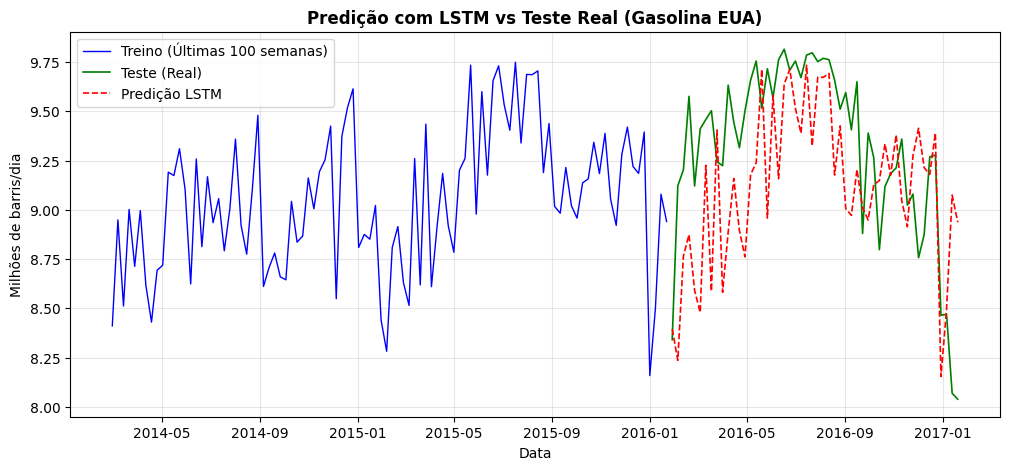

In [45]:
# Usando a melhor configuração de LSTM escolhida pela CV
tf.keras.utils.set_random_seed(42)
window_size_opt = int(melhor_lstm['window_size'])
units_opt = int(melhor_lstm['units'])
periodo_sazonal = m
horizon_teste = len(test_df) # Garante que usaremos o tamanho correto do teste (52 semanas)

# Preparando a série de treino com a diferença sazonal e escalonamento
serie_diff = train_df.Volume_Milhoes_Barris_Dia.diff(periodo_sazonal).dropna()
diferencas = serie_diff.to_numpy().reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
serie_scaled = scaler.fit_transform(diferencas)

# Criando o dataset para a LSTM
X_train_lstm, y_train_lstm = create_dataset(serie_scaled, window_size_opt)
X_train_lstm = X_train_lstm.reshape((X_train_lstm.shape[0], X_train_lstm.shape[1], 1))

# Definir e treinar o modelo LSTM
model_lstm = Sequential([
    Input(shape=(window_size_opt, 1)),
    LSTM(units=units_opt, activation='tanh'),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mse')
model_lstm.fit(X_train_lstm, y_train_lstm, epochs=20, batch_size=16, verbose=0)

# Previsão recursiva para o horizonte de teste (52 semanas)
janela = serie_scaled[-window_size_opt:].copy().reshape(1, window_size_opt, 1)
forecast_scaled = []

for _ in range(horizon_teste):
    proxima_diff_scaled = model_lstm.predict(janela, verbose=0)
    forecast_scaled.append(proxima_diff_scaled[0, 0])
    janela = np.append(janela[:, 1:, :], proxima_diff_scaled.reshape(1, 1, 1), axis=1)

forecast_scaled = np.array(forecast_scaled).reshape(-1, 1)
forecast_diff = scaler.inverse_transform(forecast_scaled).ravel()

# Reverter a diferença sazonal utilizando os valores reais do final do treino
preds_lstm = reverter_diferenca_sazonal(forecast_diff, train_df.Volume_Milhoes_Barris_Dia, periodo_sazonal)
preds_lstm_series = pd.Series(preds_lstm, index=test_df.index)

# Calcular RMSE no teste
rmse_lstm_test = root_mean_squared_error(test_df.Volume_Milhoes_Barris_Dia, preds_lstm)
print(f"RMSE do modelo LSTM no conjunto de teste: {rmse_lstm_test:.4f}")

# Plot do resultado comparando Treino, Teste e Predição
plt.figure(figsize=(12, 5))
plt.plot(train_df.Volume_Milhoes_Barris_Dia.iloc[-100:], label="Treino (Últimas 100 semanas)", color="blue", linewidth=1)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste (Real)", color="green", linewidth=1.2)
plt.plot(preds_lstm_series, label="Predição LSTM", color="red", linestyle="--", linewidth=1.2)
plt.title("Predição com LSTM vs Teste Real (Gasolina EUA)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()